## **Maestría en Inteligencia Artificial Aplicada**
### **Curso: Inteligencia Artificial y Aprendizaje Automático**
#### Tecnológico de Monterrey
#### Prof Luis Eduardo Falcón Morales

### **Actividad de la Semana: Sistemas de Recomendación basados en factorización SVD y Agentes**


**Esta Actividad deberá resolverse de manera individual.**

* **Nombre:** Eric Alejandro Moro Rebollo

* **Matrícula:** A01840718

**Modelos LLM utilizados**

* **En el agente de los ejercicios 8 y 9:** Gemini 3.8 Flash (`google/gemini-3.8-flash`), a través de la librería `google.colab.ai`, que Colab ofrece sin costo y sin clave de API. Como alternativa, el código permite usar Claude Sonnet 5.5 de Anthropic cambiando `PROVEEDOR = 'anthropic'` y guardando la clave en los Secretos de Colab.
* **Como apoyo para desarrollar la actividad:** Claude Opus 5.5 (Anthropic), a través de claude.ai.

**Incluye todas las librerías y líneas de código que consideres adecuadas.**

In [1]:
import os, re, json, time, zipfile, urllib.request, difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds
from scipy.linalg import svdvals
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize

RANDOM_STATE = 42
pd.set_option('display.max_colwidth', 60)
pd.set_option('display.width', 200)

In [2]:
# ---------- LLM del agente (ejercicio 8) ----------
# 'colab'     -> Gemini gratis desde Google Colab con google.colab.ai (no requiere clave)
# 'anthropic' -> Claude; requiere la clave ANTHROPIC_API_KEY guardada en los Secretos de Colab
PROVEEDOR = 'colab'
MODELO_CLAUDE = 'claude-sonnet-5-5'

if PROVEEDOR == 'colab':
    from google.colab import ai
    disponibles = list(ai.list_models())
    MODELO_LLM = next((m for m in disponibles if 'flash' in m and 'lite' not in m), disponibles[0])
else:
    import anthropic
    from google.colab import userdata
    cliente = anthropic.Anthropic(api_key=userdata.get('ANTHROPIC_API_KEY'))
    MODELO_LLM = MODELO_CLAUDE

def consultar_llm(prompt):
    if PROVEEDOR == 'colab':
        return ai.generate_text(prompt, model_name=MODELO_LLM)
    r = cliente.messages.create(model=MODELO_LLM, max_tokens=2000, temperature=0,
                                messages=[{'role': 'user', 'content': prompt}])
    return r.content[0].text

print('Modelo LLM utilizado:', MODELO_LLM)

Modelo LLM utilizado: google/gemini-3.8-flash


# **Ejercicio - 1: cargando datos**

In [3]:
# Descarga de MovieLens 1M (solo la primera vez)
if not os.path.exists('ml-1m/ratings.dat'):
    urllib.request.urlretrieve('https://files.grouplens.org/datasets/movielens/ml-1m.zip', 'ml-1m.zip')
    zipfile.ZipFile('ml-1m.zip').extractall()

leer = lambda archivo, columnas: pd.read_csv(f'ml-1m/{archivo}', sep='::', engine='python',
                                             names=columnas, encoding='latin-1')
movies = leer('movies.dat', ['MovieID', 'Title', 'Genres'])
ratings = leer('ratings.dat', ['UserID', 'MovieID', 'Rating', 'Timestamp'])
users = leer('users.dat', ['UserID', 'Gender', 'Age', 'Occupation', 'Zip'])

print(f"Usuarios: {users.UserID.nunique():,} (con evaluaciones: {ratings.UserID.nunique():,})")
print(f"Películas en movies.dat: {movies.MovieID.nunique():,} (con al menos una evaluación: {ratings.MovieID.nunique():,})")
print(f"Evaluaciones: {len(ratings):,}")
print(f"\nEscala: {sorted(ratings.Rating.unique())} | promedio: {ratings.Rating.mean():.2f}")
print('Distribución (%):', (ratings.Rating.value_counts(normalize=True).sort_index() * 100).round(1).to_dict())
print('Mínimo de evaluaciones por usuario:', ratings.groupby('UserID').size().min())

Usuarios: 6,040 (con evaluaciones: 6,040)
Películas en movies.dat: 3,883 (con al menos una evaluación: 3,706)
Evaluaciones: 1,000,209

Escala: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)] | promedio: 3.58
Distribución (%): {1: 5.6, 2: 10.8, 3: 26.1, 4: 34.9, 5: 22.6}
Mínimo de evaluaciones por usuario: 20


### **Respuesta**

**a)** El conjunto tiene **6,040 usuarios**, **3,883 películas** en el catálogo (`movies.dat`), de las cuales **3,706** tienen al menos una evaluación, y **1,000,209 evaluaciones**. La diferencia entre 3,883 y 3,706 es importante: las 177 películas sin evaluaciones no pueden entrar a la matriz de utilidad ni recibir factores latentes.

**b)** Las películas se evalúan en una escala **entera de 1 a 5 estrellas**, con un promedio de 3.58. La distribución está cargada hacia arriba: 4 estrellas es la calificación más común (34.9%) y el 57.5% de las evaluaciones son de 4 o 5, contra solo 16.4% de 1 o 2. Eso tiene sentido, porque la gente suele ver y calificar películas que ya esperaba que le gustaran. Además, cada usuario tiene al menos 20 evaluaciones, porque así se construyó el conjunto (Harper y Konstan, 2015).

# **Ejercicio - 2: matriz de utilidad**

In [4]:
# Matriz de utilidad: usuarios en filas y películas en columnas, guardada como matriz dispersa
usuarios = np.sort(ratings.UserID.unique())
peliculas = np.sort(ratings.MovieID.unique())
fila = {u: i for i, u in enumerate(usuarios)}
col = {m: j for j, m in enumerate(peliculas)}
ratings['u'] = ratings.UserID.map(fila)
ratings['i'] = ratings.MovieID.map(col)

def matriz(df):
    return csr_matrix((df.Rating.astype(np.float32), (df.u, df.i)), shape=(len(usuarios), len(peliculas)))

R = matriz(ratings)
densidad = R.nnz / (R.shape[0] * R.shape[1])
print(f'Dimensión: {R.shape[0]:,} usuarios x {R.shape[1]:,} películas')
print(f'Densidad: {densidad:.2%} | Dispersión (sparsity): {1 - densidad:.2%}')
mb_densa = R.shape[0] * R.shape[1] * 8 / 1e6
mb_dispersa = (R.data.nbytes + R.indices.nbytes + R.indptr.nbytes) / 1e6
print(f'Memoria como matriz densa (float64): {mb_densa:,.0f} MB | como matriz dispersa: {mb_dispersa:,.0f} MB')

# Cada usuario califica distinto (unos son más generosos que otros): se resta el promedio de cada usuario
# solo a las calificaciones que existen. Así, una celda vacía (0) significa "en su promedio".
def centrar(M):
    medias = np.asarray(M.sum(axis=1)).ravel() / np.maximum(M.getnnz(axis=1), 1)
    Mc = M.copy()
    Mc.data -= np.repeat(medias, np.diff(M.indptr)).astype(np.float32)
    return Mc, medias

Rc, medias_usuario = centrar(R)

Dimensión: 6,040 usuarios x 3,706 películas
Densidad: 4.47% | Dispersión (sparsity): 95.53%
Memoria como matriz densa (float64): 179 MB | como matriz dispersa: 8 MB


### **Respuesta**

**a)** La matriz de utilidad tiene **6,040 filas (usuarios) por 3,706 columnas (películas)**, es decir, 22,384,240 celdas. Solo 1,000,209 tienen calificación, así que su **densidad es de 4.47%** y su **dispersión (sparsity) de 95.53%**.

**b)** El valor de dispersión dice que casi toda la matriz está vacía: un usuario promedio calificó unas 166 de las 3,706 películas, y una película promedio recibió unas 270 calificaciones de 6,040 usuarios posibles. El sistema tiene que adivinar más del 95% de los gustos a partir de menos del 5%. Por eso se necesita un método como SVD, que encuentra patrones comunes entre usuarios y películas en lugar de comparar las calificaciones una por una.

**c)** Consideraciones al trabajar con matrices tan dispersas:

* **Memoria.** Guardada como matriz normal ocuparía 179 MB; como matriz dispersa (`csr_matrix`) solo se guardan las celdas con dato y ocupa 8 MB, unas 22 veces menos. Con millones de usuarios, la versión densa simplemente no cabría en memoria.
* **Algoritmos para matrices dispersas.** Se usa una SVD truncada (`svds`), que calcula solo las primeras componentes sin convertir la matriz a densa.
* **Un cero no es una mala calificación.** En la matriz, una celda vacía significa "no la ha visto", no "le dio 0 estrellas". Si se deja así, SVD aprende que las películas poco vistas son malas. Por eso a cada usuario se le resta su promedio solo en las calificaciones que existen: así una celda vacía equivale a "en su promedio" y se corrige que unos usuarios califiquen más alto que otros.
* **Pocas calificaciones, poca confianza.** Las películas con muy pocas evaluaciones tienen factores latentes poco confiables y pueden aparecer como recomendaciones extrañas. Por eso en las recomendaciones se exige un mínimo de evaluaciones.
* **Arranque en frío.** Un usuario o una película nuevos no tienen ninguna calificación, y SVD no puede ubicarlos hasta que la tengan.

# **Ejercicio - 3: varianza explicada y número de componentes latentes**

**Método.** Se calcularon todos los valores singulares de la matriz centrada. La varianza explicada por las primeras *k* componentes es la suma de sus valores singulares al cuadrado entre la suma de todos ellos. Es la "energía" que conserva la factorización truncada (Leskovec et al., 2020, cap. 11).

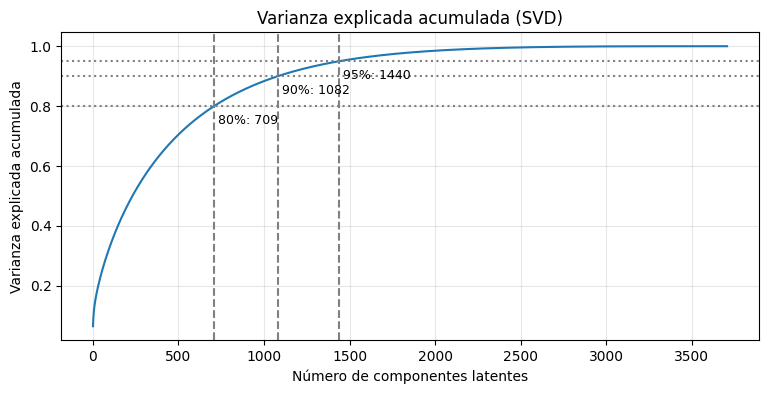

80% de varianza: 709 componentes (19% del total de 3,706)
90% de varianza: 1,082 componentes (29% del total de 3,706)
95% de varianza: 1,440 componentes (39% del total de 3,706)


In [5]:
# Valores singulares de toda la matriz (centrada) para medir la varianza explicada ("energía")
s_total = svdvals(Rc.toarray())
energia = np.cumsum(s_total ** 2) / np.sum(s_total ** 2)
umbrales = {u: int(np.argmax(energia >= u)) + 1 for u in (0.80, 0.90, 0.95)}

plt.figure(figsize=(9, 4))
plt.plot(np.arange(1, len(energia) + 1), energia)
for u, k in umbrales.items():
    plt.axhline(u, ls=':', c='gray'); plt.axvline(k, ls='--', c='gray')
    plt.text(k, u - 0.06, f' {int(u*100)}%: {k}', fontsize=9)
plt.xlabel('Número de componentes latentes'); plt.ylabel('Varianza explicada acumulada')
plt.title('Varianza explicada acumulada (SVD)'); plt.grid(alpha=0.3); plt.show()
for u, k in umbrales.items():
    print(f'{int(u*100)}% de varianza: {k:,} componentes ({k / len(s_total):.0%} del total de {len(s_total):,})')

### **Respuesta**

**a)** En la gráfica, la varianza explicada sube rápido en las primeras componentes y después se aplana poco a poco, sin un "codo" marcado. La primera componente explica apenas alrededor del 7%.

**b)** Se necesitan **709 componentes para el 80%**, **1,082 para el 90%** y **1,440 para el 95%**. Son el 19%, 29% y 39% de las 3,706 componentes posibles.

**c)** Con este criterio solo, elegiría el 80% (709 componentes) como lo más razonable: pedir 90% o 95% casi duplica las componentes para ganar poca información. Aun así, cualquiera de los tres valores es enorme para un sistema de recomendación. Que la curva no tenga un codo indica que, con una matriz tan dispersa, buena parte de la "varianza" es ruido de calificaciones individuales y no patrones de gusto compartidos. Por eso el número final se decide con el RMSE en el ejercicio 4 y se comparan ambos criterios en el ejercicio 5.

# **Ejercicio - 4: métrica RMSE y número de componentes latentes**



**Método.** Las evaluaciones se dividen en 80% para entrenamiento y 20% para prueba. La SVD se calcula solo con entrenamiento. Para cada par usuario-película de prueba, la predicción es el promedio del usuario más la reconstrucción con las primeras *k* componentes, limitada a la escala de 1 a 5. Se usa una sola SVD de 200 componentes y cada valor de *k* toma sus primeras *k*, lo que equivale a calcular una SVD truncada para cada *k*. Como referencia también se muestra el RMSE de predecir solo el promedio de cada usuario.

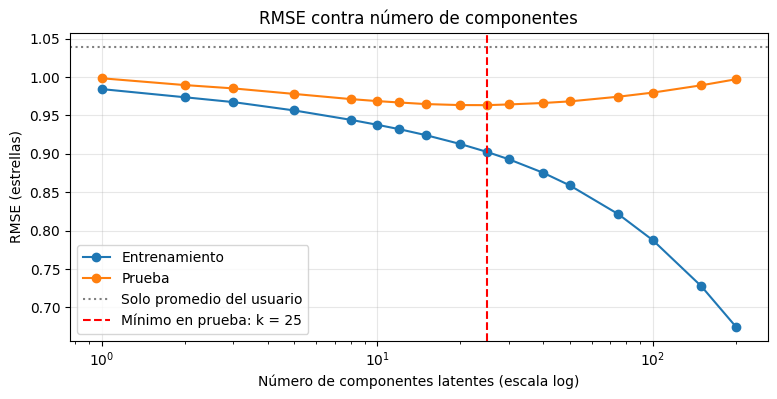

Promedio global: RMSE = 1.1197 | promedio de cada usuario: RMSE = 1.0394
                       1       2       3       5       8       10      12      15      20      25      30      40      50      75      100     150     200
RMSE entrenamiento  0.9841  0.9735  0.9672  0.9563  0.9442  0.9377  0.9320  0.9242  0.9127  0.9024  0.8928  0.8752  0.8587  0.8212  0.7874  0.7274  0.6749
RMSE prueba         0.9982  0.9894  0.9851  0.9778  0.9711  0.9685  0.9667  0.9646  0.9633  0.9632  0.9642  0.9661  0.9682  0.9742  0.9796  0.9891  0.9969

Menor RMSE de prueba: k = 25 con 0.9632


In [6]:
# 80% entrenamiento y 20% prueba de las evaluaciones
train, test = train_test_split(ratings, test_size=0.20, random_state=RANDOM_STATE)
Rc_tr, medias_tr = centrar(matriz(train))

# Una sola SVD truncada con K_MAX componentes; los modelos con k menor usan sus primeras k componentes
K_MAX = 200
U, s, Vt = svds(Rc_tr, k=K_MAX, random_state=RANDOM_STATE)
orden = np.argsort(s)[::-1]
U, s, Vt = U[:, orden], s[orden], Vt[orden]

K_LISTA = [1, 2, 3, 5, 8, 10, 12, 15, 20, 25, 30, 40, 50, 75, 100, 150, 200]

def rmse_por_k(df):
    # predicción = promedio del usuario + suma de las k primeras componentes
    u, i, real = df.u.values, df.i.values, df.Rating.values
    pred = medias_tr[u].astype(np.float64)
    res = {0: np.sqrt(np.mean((real - np.clip(pred, 1, 5)) ** 2))}
    for j in range(K_MAX):
        pred += U[u, j] * s[j] * Vt[j, i]
        if j + 1 in K_LISTA:
            res[j + 1] = np.sqrt(np.mean((real - np.clip(pred, 1, 5)) ** 2))
    return res

rmse_test = rmse_por_k(test)
rmse_train = rmse_por_k(train)
rmse_global = np.sqrt(np.mean((test.Rating - train.Rating.mean()) ** 2))
K_RMSE = min(K_LISTA, key=lambda k: rmse_test[k])

plt.figure(figsize=(9, 4))
plt.plot(K_LISTA, [rmse_train[k] for k in K_LISTA], 'o-', label='Entrenamiento')
plt.plot(K_LISTA, [rmse_test[k] for k in K_LISTA], 'o-', label='Prueba')
plt.axhline(rmse_test[0], ls=':', c='gray', label='Solo promedio del usuario')
plt.axvline(K_RMSE, ls='--', c='red', label=f'Mínimo en prueba: k = {K_RMSE}')
plt.xscale('log'); plt.xlabel('Número de componentes latentes (escala log)'); plt.ylabel('RMSE (estrellas)')
plt.title('RMSE contra número de componentes'); plt.legend(); plt.grid(alpha=0.3); plt.show()

print(f'Promedio global: RMSE = {rmse_global:.4f} | promedio de cada usuario: RMSE = {rmse_test[0]:.4f}')
print(pd.DataFrame({'RMSE entrenamiento': rmse_train, 'RMSE prueba': rmse_test}).loc[K_LISTA].round(4).T.to_string())
print(f'\nMenor RMSE de prueba: k = {K_RMSE} con {rmse_test[K_RMSE]:.4f}')

### **Respuesta**

**a)** Las 1,000,209 evaluaciones se dividieron en 80% para entrenamiento y 20% para prueba, con `random_state=42`.

**b)** Con la SVD entrenada, el mejor resultado en prueba es un **RMSE de 0.9632 estrellas con 25 componentes**. Como referencia:

| Modelo | RMSE en prueba |
|---|---|
| Predecir siempre el promedio global | 1.1197 |
| Predecir el promedio de cada usuario | 1.0394 |
| **SVD con 25 componentes** | **0.9632** |

La SVD reduce el error 7.3% respecto al promedio de cada usuario y 14% respecto al promedio global.

**c)** La gráfica muestra el comportamiento típico de sobreentrenamiento:
* **En entrenamiento** el error baja siempre al agregar componentes: de 0.98 con una componente a 0.67 con 200.
* **En prueba** baja hasta un mínimo entre 20 y 30 componentes y después **sube**: con 200 componentes llega a 0.9969, casi tan mal como con una sola.

A partir de ese punto, las componentes extra ya no aprenden gustos, sino el ruido de cada calificación.

**d)** Elijo **25 componentes**. Es el mínimo de la curva de prueba, aunque la zona de 20 a 30 es prácticamente plana (0.9633, 0.9632 y 0.9642), así que cualquier valor en ese rango daría casi lo mismo. Dentro de esa zona, 25 es el punto medio y mantiene un modelo pequeño y rápido.

# **Ejercicio - 5: comparación varianza explicada vs RMSE**

In [7]:
K_FINAL = K_RMSE
criterios = {'80% de varianza': umbrales[0.80], '90% de varianza': umbrales[0.90],
             '95% de varianza': umbrales[0.95], 'Menor RMSE de prueba': K_RMSE}
tabla5 = pd.DataFrame({'Componentes': criterios,
                       'Varianza explicada (%)': {c: round(100 * energia[k - 1], 1) for c, k in criterios.items()},
                       'RMSE de prueba': {c: round(rmse_test[k], 4) if k in rmse_test else 'mayor que K_MAX' for c, k in criterios.items()}})
tabla5

,Componentes,Varianza explicada (%),RMSE de prueba
80% de varianza,709,80.000000,mayor que K_MAX
90% de varianza,1082,90.000000,mayor que K_MAX
95% de varianza,1440,95.000000,mayor que K_MAX
Menor RMSE de prueba,25,18.299999,0.9632


### **Respuesta**

Los dos criterios dan respuestas muy distintas. Por varianza explicada se necesitarían entre 709 y 1,440 componentes. Por RMSE, el mejor valor es **25**, que explica apenas el 18.3% de la varianza.

**Elijo 25 componentes**, por tres razones:

1. **El objetivo es predecir, no reconstruir.** Un sistema de recomendación vale por lo bien que adivina gustos nuevos, que es lo que mide el RMSE de prueba. La varianza explicada solo mide cuánta información de la matriz se conserva, incluido el ruido.
2. **Más componentes empeoran la predicción.** La curva del ejercicio 4 ya va subiendo en 200 componentes (0.9969), así que 709 o más estarían todavía más sobreentrenadas.
3. **Es mucho más barato.** Con 25 factores por película, calcular similitudes y guardar el modelo cuesta una fracción de lo que costaría con cientos.

El resto de la actividad usa `K_FINAL = 25`.

# **Ejercicio - 6: sistema de recomendación colaborativo**

In [8]:
# SVD truncada con todas las evaluaciones y K_FINAL componentes: factores latentes de cada película
U_f, s_f, Vt_f = svds(Rc, k=K_FINAL, random_state=RANDOM_STATE)
orden = np.argsort(s_f)[::-1]
factores_svd = (Vt_f[orden].T * s_f[orden])           # películas x K_FINAL

sim_svd = cosine_similarity(factores_svd)
print('Dimensión de la matriz de similitud:', sim_svd.shape)

# Catálogo con título, géneros, año y número de evaluaciones, en el mismo orden que las columnas
catalogo = movies.set_index('MovieID').loc[peliculas].reset_index()
catalogo['Año'] = catalogo.Title.str.extract(r'\((\d{4})\)\s*$').astype(int)
catalogo['Evaluaciones'] = ratings.groupby('MovieID').size().loc[peliculas].values
MIN_EVAL = 50   # solo se recomiendan películas con al menos 50 evaluaciones (sus factores son más confiables)

def buscar(titulo):
    if titulo in set(catalogo.Title):
        return int(catalogo.index[catalogo.Title == titulo][0])
    parecido = difflib.get_close_matches(titulo, catalogo.Title.tolist(), n=1, cutoff=0.6)
    if not parecido:
        raise ValueError(f'No se encontró la película: {titulo}')
    print(f'"{titulo}" se interpretó como "{parecido[0]}"')
    return int(catalogo.index[catalogo.Title == parecido[0]][0])

def recomendar(similitudes, excluir, n=10):
    sims = pd.Series(similitudes, index=catalogo.index).drop(excluir)
    sims = sims[catalogo.loc[sims.index, 'Evaluaciones'] >= MIN_EVAL].sort_values(ascending=False).head(n)
    return pd.DataFrame({'Película': catalogo.loc[sims.index, 'Title'].values,
                         'Géneros': catalogo.loc[sims.index, 'Genres'].values,
                         'Similitud': sims.values.round(3)}, index=range(1, n + 1))

PELICULA = 'Matrix, The (1999)'
idx_peli = buscar(PELICULA)
print(f'\nRecomendaciones por SVD para {catalogo.Title[idx_peli]} ({catalogo.Genres[idx_peli]}):')
recs_svd = recomendar(sim_svd[idx_peli], [idx_peli])
recs_svd

Dimensión de la matriz de similitud: (3706, 3706)

Recomendaciones por SVD para Matrix, The (1999) (Action|Sci-Fi|Thriller):


,Película,Géneros,Similitud
1,Terminator 2: Judgment Day (1991),Action|Sci-Fi|Thriller,0.815
2,"Terminator, The (1984)",Action|Sci-Fi|Thriller,0.728
3,Gladiator (2000),Action|Drama,0.703
4,"Professional, The (a.k.a. Leon: The Professional) (1994)",Crime|Drama|Romance|Thriller,0.685
5,Twelve Monkeys (1995),Drama|Sci-Fi,0.679
6,"Sixth Sense, The (1999)",Thriller,0.679
7,Aliens (1986),Action|Sci-Fi|Thriller|War,0.674
8,"Game, The (1997)",Mystery|Thriller,0.657
9,Braveheart (1995),Action|Drama|War,0.655
10,"Princess Bride, The (1987)",Action|Adventure|Comedy|Romance,0.655


### **Respuesta**

**a) y b)** La matriz de similitud del coseno entre los factores latentes de las películas es de **3,706 × 3,706**: una fila y una columna por cada película con evaluaciones. Es simétrica y su diagonal vale 1.

**c)** Elegí **The Matrix (1999)**. Sus 10 recomendaciones por SVD, con su similitud, están en la tabla de arriba. Van de Terminator 2 (0.815) a The Princess Bride (0.655).

**d)** En general **sí son coherentes**:
* Las más esperadas son las de ciencia ficción y acción: Terminator 2 y The Terminator en los primeros lugares, y más abajo Aliens y Twelve Monkeys.
* Gladiator, Léon (The Professional), The Sixth Sense y The Game no comparten todos los géneros, pero sí el perfil de "película de acción o suspenso de finales de los 90" que suele gustarle al mismo público.

Lo menos esperado son **Braveheart** y **The Princess Bride**. No se parecen a The Matrix por contenido. Aparecen porque son muy populares entre el mismo tipo de usuario, que es justo cómo funciona el filtrado colaborativo: no sabe qué tratan las películas, solo quién las ve. Es un ejemplo del **sesgo de popularidad**.

**e) Explicación para alguien no experto.** Imagina que cada película tiene unas cuantas "perillas" invisibles que describen su estilo: qué tan de acción es, qué tan seria, qué tan para toda la familia, qué tan clásica. Nadie le dijo al sistema cuáles son esas perillas: las descubrió solo, viendo qué películas tienden a gustarle a las mismas personas. Si a quienes les encanta *The Matrix* también les suelen gustar *Terminator 2* y *Aliens*, el sistema concluye que esas películas tienen las perillas en posiciones parecidas. Para recomendar, busca las películas cuyas perillas están más cerca de las de la película que te gustó. La similitud del coseno mide esa cercanía: 1 significa que apuntan exactamente en la misma dirección y 0 que no tienen nada en común.

# **Ejercicio - 7: sistema de recomendación híbrido**

In [9]:
# a) Década de estreno (one-hot)
decada = (catalogo['Año'] // 10 * 10).astype(str) + 's'
B_decada = pd.get_dummies(decada).astype(float)

# b) Géneros (una columna por género) y dos factores de users.dat agregados por película:
#    porcentaje de mujeres entre quienes la calificaron y edad promedio de quienes la calificaron.
#    Igual que con el año, ambos se agrupan en tres niveles (terciles) y se codifican con one-hot.
B_genero = catalogo.Genres.str.get_dummies('|').astype(float)
EDAD = {1: 15, 18: 21, 25: 30, 35: 40, 45: 47, 50: 52, 56: 60}       # punto medio de cada rango de edad
ru = ratings.merge(users[['UserID', 'Gender', 'Age']], on='UserID')
perfil = ru.assign(mujer=ru.Gender.eq('F'), edad=ru.Age.map(EDAD)).groupby('MovieID')[['mujer', 'edad']].mean().loc[peliculas]
nivel_mujeres = pd.qcut(perfil.mujer.values, 3, labels=['pocas mujeres', 'mixto', 'muchas mujeres'])
nivel_edad = pd.qcut(perfil.edad.values, 3, labels=['público joven', 'público medio', 'público mayor'])
B_publico = pd.get_dummies(pd.DataFrame({'mujeres': nivel_mujeres, 'edad': nivel_edad})).astype(float)

# c) Matriz híbrida: cada bloque se normaliza (longitud 1) y se multiplica por la raíz de su peso.
#    Así, la similitud del coseno híbrida es exactamente el promedio ponderado de las similitudes de cada bloque.
PESOS = {'svd': 0.55, 'genero': 0.25, 'decada': 0.10, 'publico': 0.10}
bloques = {'svd': factores_svd, 'genero': B_genero.values, 'decada': B_decada.values, 'publico': B_publico.values}
H = np.hstack([np.sqrt(PESOS[b]) * normalize(bloques[b]) for b in bloques])
print('Dimensión de la matriz híbrida:', H.shape,
      f"= {K_FINAL} factores SVD + {B_genero.shape[1]} géneros + {B_decada.shape[1]} décadas + {B_publico.shape[1]} niveles de público")

sim_hib = cosine_similarity(H)
recs_hib = recomendar(sim_hib[idx_peli], [idx_peli])
comparacion = pd.concat({'SVD': recs_svd[['Película', 'Similitud']], 'Híbrido': recs_hib[['Película', 'Similitud']]}, axis=1)
print(f'\nTop 10 para {catalogo.Title[idx_peli]}:')
comparacion

Dimensión de la matriz híbrida: (3706, 59) = 25 factores SVD + 18 géneros + 10 décadas + 6 niveles de público

Top 10 para Matrix, The (1999):


SVD                                      Híbrido          
                                                    Película Similitud                           Película Similitud
1                          Terminator 2: Judgment Day (1991)     0.815  Terminator 2: Judgment Day (1991)     0.848
2                                     Terminator, The (1984)     0.728               Fugitive, The (1993)     0.752
3                                           Gladiator (2000)     0.703            Sixth Sense, The (1999)     0.718
4   Professional, The (a.k.a. Leon: The Professional) (1994)     0.685             Terminator, The (1984)     0.700
5                                      Twelve Monkeys (1995)     0.679    Nikita (La Femme Nikita) (1990)     0.677
6                                    Sixth Sense, The (1999)     0.679   Hunt for Red October, The (1990)     0.668
7                                              Aliens (1986)     0.674                Total Recall (1990)     0.663
8                                           Game, The (1997)     0.657                     Gattaca (1997)     0.654
9                                          Braveheart (1995)     0.655                  Braveheart (1995)     0.644
10                                Princess Bride, The (1987)     0.655                      Aliens (1986)     0.637

### **Respuesta (incisos a, b y d)**

**a) Década.** Se extrae el año del título, que viene entre paréntesis, y se agrupa en décadas (1910s a 2000s, 10 décadas). Se codifica con one-hot: una columna por década. Agrupar por década en lugar de usar el año exacto evita que dos películas de 1994 y 1995 parezcan distintas, y captura algo que sí importa en el gusto, como la época, el estilo de filmación o los clásicos frente a los estrenos.

**b) Género y dos factores de `users.dat`.**
* **Género:** una columna por cada uno de los 18 géneros, porque una película puede tener varios.
* **Porcentaje de mujeres entre quienes la calificaron** y **edad promedio de quienes la calificaron.** `users.dat` describe usuarios, no películas, así que se agregan por película para obtener el perfil de su público. La edad viene en rangos codificados (1, 18, 25…), así que se usa el punto medio de cada rango.
* Igual que con el año, cada uno de estos dos factores se agrupa en tres niveles (terciles) y se codifica con one-hot: "pocas mujeres / mixto / muchas mujeres" y "público joven / medio / mayor".

Elegí estos factores porque describen dos cosas que SVD no ve directamente: **qué es la película** (género y década) y **quién la ve** (sexo y edad de su público). La ocupación y el código postal se descartaron porque tienen muchas categorías con pocos usuarios y aportarían más ruido que información.

**Cómo se combinan.** Cada bloque (factores SVD, géneros, décadas y público) se normaliza a longitud 1 y se multiplica por la raíz de su peso: 0.55 para SVD, 0.25 para género, 0.10 para década y 0.10 para público. Con esa construcción, la similitud del coseno híbrida es exactamente el promedio ponderado de las similitudes de cada bloque, así que los pesos se pueden interpretar directamente. SVD conserva el mayor peso porque es la única fuente que refleja gustos reales.

**d) Beneficios de la matriz aumentada.**
* **Coherencia temática:** las recomendaciones comparten género y época con la película elegida, algo que SVD solo logra de manera indirecta.
* **Menos ruido:** si dos películas coinciden en SVD por casualidad, pero no tienen nada que ver en género ni época, la similitud híbrida baja.
* **Arranque en frío:** una película nueva sin calificaciones no tiene factores SVD, pero sí género y década, así que se le puede ubicar desde el primer día.
* **Interpretabilidad:** se puede explicar una recomendación ("misma década, mismo género, público parecido"), cosa que con factores latentes no es posible.

### **Respuesta (incisos c, e y f)**

**c)** La matriz híbrida es de **3,706 × 59**: 25 factores SVD, 18 géneros, 10 décadas (de 1910 a 2000) y 6 niveles de público (3 por porcentaje de mujeres y 3 por edad).

**e)** La tabla comparativa de las 10 recomendaciones de The Matrix, con su similitud en cada método, está arriba.

**f)** Las dos listas comparten 5 películas: Terminator 2, The Terminator, The Sixth Sense, Braveheart y Aliens. Terminator 2 queda primera en ambas, y en el híbrido con más similitud (0.848 contra 0.815), porque además coincide en géneros.

* **Salen del híbrido:** Gladiator, Léon, Twelve Monkeys, The Game y The Princess Bride, que se parecían a The Matrix solo por su público.
* **Entran:** The Fugitive, Nikita, The Hunt for Red October, Total Recall y Gattaca, todas de acción, suspenso o ciencia ficción, y todas de los 90.

El híbrido se ve **más coherente temáticamente**: desaparece The Princess Bride, que era la recomendación más extraña. A cambio, pierde un poco de la "sorpresa" del filtrado colaborativo. Entran varias películas de los 90 en parte porque el bloque de década premia la misma época, aunque Total Recall y Gattaca sí son ciencia ficción. El resultado depende de los pesos, que aquí elegí a criterio (0.55 para SVD). Con más tiempo, lo ideal sería ajustarlos con una métrica de evaluación, como medir qué tanto aciertan las recomendaciones con películas que los usuarios calificaron después.

# **Ejercicio - 8: sistema de recomendación mediante un agente inteligente**

In [10]:
# a) El usuario indica sus 5 películas favoritas. Su perfil es el promedio de los vectores de esas películas.
def candidatos(favoritas, n=10):
    idx = [buscar(t) for t in favoritas]
    perfil_svd = normalize(factores_svd)[idx].mean(axis=0, keepdims=True)
    perfil_hib = H[idx].mean(axis=0, keepdims=True)
    svd_ = recomendar(cosine_similarity(perfil_svd, factores_svd).ravel(), idx, n)
    hib_ = recomendar(cosine_similarity(perfil_hib, H).ravel(), idx, n)
    return [catalogo.Title[i] for i in idx], svd_, hib_

FAVORITAS = ['Pulp Fiction (1994)', 'Godfather, The (1972)', 'Usual Suspects, The (1995)',
             'Silence of the Lambs, The (1991)', 'Fargo (1996)']
favs, cand_svd, cand_hib = candidatos(FAVORITAS)
print('Favoritas del usuario:', favs)
pd.concat({'SVD': cand_svd[['Película', 'Similitud']], 'Híbrido': cand_hib[['Película', 'Similitud']]}, axis=1)

Favoritas del usuario: ['Pulp Fiction (1994)', 'Godfather, The (1972)', 'Usual Suspects, The (1995)', 'Silence of the Lambs, The (1991)', 'Fargo (1996)']


SVD                                                             Híbrido          
                                   Película Similitud                                                  Película Similitud
1                         GoodFellas (1990)     0.893                                         GoodFellas (1990)     0.905
2                  L.A. Confidential (1997)     0.880                                        Sling Blade (1996)     0.867
3                        Sling Blade (1996)     0.866                                  L.A. Confidential (1997)     0.822
4    One Flew Over the Cuckoo's Nest (1975)     0.831                          Shawshank Redemption, The (1994)     0.783
5                     Reservoir Dogs (1992)     0.826  Professional, The (a.k.a. Leon: The Professional) (1994)     0.780
6                      Seven (Se7en) (1995)     0.809                                      Seven (Se7en) (1995)     0.779
7   Some Folks Call It a Sling Blade (1993)     0.799                   Some Folks Call It a Sling Blade (1993)     0.773
8                        Hoop Dreams (1994)     0.784                            Godfather: Part II, The (1974)     0.757
9            Godfather: Part II, The (1974)     0.783                                              Bound (1996)     0.755
10         Shawshank Redemption, The (1994)     0.782                                      Donnie Brasco (1997)     0.752

**Diseño del agente.** El agente recibe las favoritas del usuario y las dos listas de candidatas, con géneros y similitud. Para reducir el riesgo de alucinaciones tiene tres controles:
1. **El prompt solo le permite elegir entre las candidatas** y le prohíbe inventar datos que no se le dieron.
2. **Debe responder en JSON**, para poder leer la respuesta automáticamente.
3. **El código verifica cada título** contra las listas de candidatas. Si el LLM escribe una película que no está, se marca como alucinación; si cambia ligeramente el título, se marca como "título alterado".

Así, el LLM no decide qué películas existen: solo ordena, elige y explica a partir de lo que calcularon SVD y el sistema híbrido.

In [11]:
# b), c) y d) Agente: recibe las favoritas y las dos listas, y elige 5 películas justificadas
PROMPT = """Eres un agente experto en recomendación de películas. Tu tarea es elegir las 5 mejores
recomendaciones finales para un usuario a partir de la información que te doy. No uses ninguna otra fuente.

PELÍCULAS FAVORITAS DEL USUARIO:
{favoritas}

CANDIDATAS DEL SISTEMA SVD (filtrado colaborativo: usuarios con gustos parecidos las calificaron de forma similar):
{lista_svd}

CANDIDATAS DEL SISTEMA HÍBRIDO (SVD + género + década + perfil del público):
{lista_hib}

REGLAS:
1. Elige exactamente 5 películas y SOLO de las listas de candidatas. Escribe cada título exactamente como aparece.
2. No recomiendes ninguna de las películas favoritas.
3. Da prioridad a las películas que aparecen en ambas listas o que tienen mayor similitud, pero cuida que
   las 5 no sean todas iguales entre sí: busca un poco de variedad dentro de los gustos del usuario.
4. Justifica cada película en una o dos oraciones, en español, con base en los géneros, la década, la
   similitud y su relación con las favoritas. No inventes datos (actores, directores, premios o tramas)
   que no estén en la información proporcionada.
5. Responde únicamente con un JSON válido con esta estructura, sin texto adicional:
{{"recomendaciones": [{{"titulo": "...", "fuente": "SVD | Híbrido | Ambas", "justificacion": "..."}}]}}"""

def describir(df):
    return '\n'.join(f"- {r['Película']} | géneros: {r['Géneros']} | similitud: {r['Similitud']}" for _, r in df.iterrows())

def agente(favoritas):
    favs, c_svd, c_hib = candidatos(favoritas)
    info_favs = '\n'.join(f"- {t} | géneros: {catalogo.Genres[buscar(t)]}" for t in favs)
    prompt = PROMPT.format(favoritas=info_favs, lista_svd=describir(c_svd), lista_hib=describir(c_hib))
    texto = consultar_llm(prompt)
    datos = json.loads(re.search(r'\{.*\}', texto, re.S).group(0))
    validas = set(c_svd['Película']) | set(c_hib['Película'])
    filas = []
    for r in datos['recomendaciones']:
        exacta = r['titulo'] in validas
        cercana = difflib.get_close_matches(r['titulo'], list(validas), n=1, cutoff=0.9)
        filas.append({'Película': r['titulo'], 'Fuente': r['fuente'],
                      'En candidatas': 'Sí' if exacta else ('Título alterado' if cercana else 'NO (alucinación)'),
                      'Justificación': r['justificacion']})
    return pd.DataFrame(filas, index=range(1, len(filas) + 1)), prompt, c_svd, c_hib

resultado, prompt_usado, _, _ = agente(FAVORITAS)
print('Modelo LLM:', MODELO_LLM)
pd.set_option('display.max_colwidth', None)
resultado

Modelo LLM: google/gemini-3.8-flash


,Película,Fuente,En candidatas,Justificación
1,GoodFellas (1990),Ambas,Sí,Lidera ambas listas con la puntuación de similitud más alta (0.893 en SVD y 0.905 en Híbrido) y comparte los géneros Crime y Drama con las favoritas Pulp Fiction y The Godfather.
2,L.A. Confidential (1997),Ambas,Sí,"Presenta una alta similitud en ambos sistemas y aporta variedad incorporando Film-Noir y Mystery, manteniendo la base de Crime y Thriller de películas favoritas de los años noventa como Fargo y The Usual Suspects."
3,Sling Blade (1996),Ambas,Sí,Cuenta con una destacada similitud en ambos modelos (0.866 en SVD y 0.867 en Híbrido) y coincide en la década de 1990 y la combinación Drama y Thriller con The Silence of the Lambs.
4,"Godfather: Part II, The (1974)",Ambas,Sí,"Aparece en ambas listas y comparte la década de 1970 junto con la combinación exacta de géneros Action, Crime y Drama con su predecesora favorita, The Godfather."
5,Seven (Se7en) (1995),Ambas,Sí,Figura con sólida similitud en ambas listas y se alinea directamente con la década de 1990 y los géneros Crime y Thriller de The Usual Suspects y Fargo.


In [12]:
# d) Prompt completo enviado al LLM en este ejercicio
print(prompt_usado)

Eres un agente experto en recomendación de películas. Tu tarea es elegir las 5 mejores
recomendaciones finales para un usuario a partir de la información que te doy. No uses ninguna otra fuente.

PELÍCULAS FAVORITAS DEL USUARIO:
- Pulp Fiction (1994) | géneros: Crime|Drama
- Godfather, The (1972) | géneros: Action|Crime|Drama
- Usual Suspects, The (1995) | géneros: Crime|Thriller
- Silence of the Lambs, The (1991) | géneros: Drama|Thriller
- Fargo (1996) | géneros: Crime|Drama|Thriller

CANDIDATAS DEL SISTEMA SVD (filtrado colaborativo: usuarios con gustos parecidos las calificaron de forma similar):
- GoodFellas (1990) | géneros: Crime|Drama | similitud: 0.8930000066757202
- L.A. Confidential (1997) | géneros: Crime|Film-Noir|Mystery|Thriller | similitud: 0.8799999952316284
- Sling Blade (1996) | géneros: Drama|Thriller | similitud: 0.8659999966621399
- One Flew Over the Cuckoo's Nest (1975) | géneros: Drama | similitud: 0.8309999704360962
- Reservoir Dogs (1992) | géneros: Crime|Thri

### **Respuesta (incisos a, b y c)**

**a)** Para un usuario cuyas favoritas son Pulp Fiction, The Godfather, The Usual Suspects, The Silence of the Lambs y Fargo, la tabla de arriba compara las 10 recomendaciones de cada método. Las dos listas comparten 7 películas. GoodFellas queda primera en ambas, con 0.893 en SVD y 0.905 en el híbrido.

La diferencia más interesante está en lo que cada método agrega por su cuenta:
* **SVD** incluye *Hoop Dreams*, un documental, y *One Flew Over the Cuckoo's Nest*. Se parecen por su público, que valora el cine aclamado de los 90, no por su género.
* **El híbrido** las cambia por Léon, Bound y Donnie Brasco, que sí son de crimen y suspenso.

**b) y c)** El agente, con Gemini 3.8 Flash, eligió GoodFellas, L.A. Confidential, Sling Blade, The Godfather Part II y Seven, y justificó cada una:
* **Las 5 están en ambas listas**, como pedía la regla de prioridad.
* **No hay títulos inventados.**
* **Las justificaciones solo usan la información que recibió:** géneros, décadas y similitudes. Cuando cita cifras, coinciden exactamente con las candidatas; por ejemplo, 0.893 y 0.905 para GoodFellas.
* **Se nota variedad dentro del gusto del usuario:** incluye L.A. Confidential, que agrega cine negro y misterio, y descarta el documental y el cortometraje *Some Folks Call It a Sling Blade*, aunque tenían similitud alta.

**d)** El prompt completo está en la celda anterior. Un detalle técnico: las similitudes de SVD aparecen con muchos decimales, por el tipo de dato `float32`. No afectó la respuesta, pero en producción convendría redondearlas antes de enviarlas.

# **Ejercicio - 9: Evaluación del agente**

In [13]:
# Evaluación con tres usuarios de gustos muy distintos
PERFILES = {
    'Animación y familia': ['Toy Story (1995)', 'Lion King, The (1994)', 'Aladdin (1992)',
                            'Beauty and the Beast (1991)', 'Little Mermaid, The (1989)'],
    'Ciencia ficción y acción': ['Matrix, The (1999)', 'Terminator 2: Judgment Day (1991)',
                                 'Star Wars: Episode IV - A New Hope (1977)', 'Alien (1979)', 'Blade Runner (1982)'],
    'Clásicos de drama y romance': ['Casablanca (1942)', 'Roman Holiday (1953)', 'Gone with the Wind (1939)',
                                    'Sound of Music, The (1965)', 'African Queen, The (1951)'],
}

def comparte_genero(titulo, favoritas):
    if titulo not in set(catalogo.Title):
        return False
    gen_favs = set('|'.join(catalogo.Genres[buscar(t)] for t in favoritas).split('|'))
    return bool(set(catalogo.Genres[buscar(titulo)].split('|')) & gen_favs)

resumen, detalle = [], {}
for nombre, favs in PERFILES.items():
    res, _, c_svd, c_hib = agente(favs)
    detalle[nombre] = res
    resumen.append({'Perfil': nombre,
                    'Recomendaciones': ' / '.join(res['Película']),
                    'Dentro de candidatas': f"{(res['En candidatas'] == 'Sí').sum()} de {len(res)}",
                    'Alucinaciones': int((res['En candidatas'] == 'NO (alucinación)').sum()),
                    'Comparten género con favoritas': f"{sum(comparte_genero(t, favs) for t in res['Película'])} de {len(res)}",
                    'Coincidencias SVD-Híbrido en candidatas': len(set(c_svd['Película']) & set(c_hib['Película']))})
resumen = pd.DataFrame(resumen)
resumen

,Perfil,Recomendaciones,Dentro de candidatas,Alucinaciones,Comparten género con favoritas,Coincidencias SVD-Híbrido en candidatas
0,Animación y familia,"Mulan (1998) / Bug's Life, A (1998) / Tarzan (1999) / Cinderella (1950) / Lady and the Tramp (1955)",5 de 5,0,5 de 5,7
1,Ciencia ficción y acción,"Terminator, The (1984) / Aliens (1986) / Star Wars: Episode V - The Empire Strikes Back (1980) / Raiders of the Lost Ark (1981) / Close Encounters of the Third Kind (1977)",5 de 5,0,5 de 5,6
2,Clásicos de drama y romance,"My Fair Lady (1964) / Singin' in the Rain (1952) / Philadelphia Story, The (1940) / From Here to Eternity (1953) / Mr. Smith Goes to Washington (1939)",5 de 5,0,5 de 5,4


In [14]:
# Detalle de las justificaciones del agente para cada perfil
for nombre, res in detalle.items():
    print(f'\n===== {nombre} =====')
    for i, r in res.iterrows():
        print(f"{i}. {r['Película']} [{r['Fuente']}] ({r['En candidatas']})\n   {r['Justificación']}")


===== Animación y familia =====
1. Mulan (1998) [Ambas] (Sí)
   Registra la mayor similitud en ambos modelos (0.917 en SVD y 0.897 en Híbrido) y pertenece a la década de 1990, coincidiendo en época y en los géneros Animation y Children's con favoritas como The Lion King y Aladdin.
2. Bug's Life, A (1998) [Ambas] (Sí)
   Obtiene alta afinidad en ambas listas y replica con exactitud los géneros Animation, Children's y Comedy de Toy Story, aportando variedad dentro de la comedia animada de los años 90.
3. Tarzan (1999) [Ambas] (Sí)
   Presenta puntuaciones sobresalientes en ambos sistemas (0.860 en SVD y 0.865 en Híbrido) y comparte los géneros Animation y Children's de la era noventera predilecta del usuario.
4. Cinderella (1950) [Ambas] (Sí)
   Figura con alta similitud en ambos modelos y coincide en los géneros Animation, Children's y Musical con Beauty and the Beast, aportando variedad histórica como clásico de la década de 1950.
5. Lady and the Tramp (1955) [Ambas] (Sí)
   Aparece r

### **Respuesta**

**a) Resumen.** El agente se probó con tres usuarios de gustos muy distintos:

| Perfil | Recomendaciones del agente | En candidatas | Alucinaciones | Comparten género |
|---|---|---|---|---|
| Animación y familia | Mulan, A Bug's Life, Tarzan, Cinderella, Lady and the Tramp | 5 de 5 | 0 | 5 de 5 |
| Ciencia ficción y acción | The Terminator, Aliens, The Empire Strikes Back, Raiders of the Lost Ark, Close Encounters of the Third Kind | 5 de 5 | 0 | 5 de 5 |
| Clásicos de drama y romance | My Fair Lady, Singin' in the Rain, The Philadelphia Story, From Here to Eternity, Mr. Smith Goes to Washington | 5 de 5 | 0 | 5 de 5 |

**b) Coherencia y alucinaciones.** Las 15 recomendaciones son coherentes con cada perfil:
* animación de Disney y Pixar para el primero;
* clásicos de ciencia ficción y aventura de los 70 y 80 para el segundo;
* clásicos de 1939 a 1964 para el tercero, sobre todo musicales y romances.

**No detecté alucinaciones de títulos**: las 15 películas están en las listas de candidatas. Los géneros que menciona en las justificaciones también coinciden con el catálogo. Una limitación: en estos tres perfiles la celda no muestra las listas de candidatas, así que las cifras de similitud que cita el agente (por ejemplo, 0.917 para Mulan) no se verificaron de forma automática como en el ejercicio 8.

**c) Comentarios.**
* **Se adapta bien a cada perfil** y en los tres casos prefiere películas que aparecen en ambas listas.
* **Su principal debilidad es que puede ser predecible.** En ciencia ficción eligió secuelas o películas de las mismas franquicias que las favoritas (The Terminator, Aliens, The Empire Strikes Back). Son recomendaciones correctas, pero el usuario probablemente ya las conoce.
* **Su variedad es limitada:** cuando dice que agrega variedad, en realidad se mueve poco, por ejemplo de los 90 a un clásico de los 50 en animación.
* **Las coincidencias entre las listas de SVD e híbrido bajan** de 7 en animación a 4 en clásicos. En perfiles con menos películas populares los dos métodos discrepan más, y ahí es donde el agente aporta más al combinarlos.

**d) Comparación de los tres métodos**

| Criterio | SVD | Híbrido (SVD + contenido) | Agente con LLM |
|---|---|---|---|
| **Personalización** | Media. Usa los gustos de usuarios parecidos, pero no sabe por qué se parecen | Media-alta. Agrega género, época y público | Alta. Combina las dos listas y adapta la selección y la explicación al usuario |
| **Interpretabilidad** | Baja. Los factores latentes no tienen nombre | Media. Se puede decir qué bloque pesó más | Alta en apariencia: explica cada película en lenguaje natural, aunque la explicación la genera el LLM y hay que verificarla |
| **Mantenimiento** | Bajo. Recalcular la SVD cada cierto tiempo | Medio. También hay que mantener los catálogos y elegir los pesos | Alto. Depende de un proveedor externo, de versiones del modelo y del prompt, y requiere monitorear las respuestas |
| **Costo computacional** | Bajo. La SVD se calcula una vez y recomendar es una multiplicación | Bajo. Similar a SVD | Alto. Cada recomendación es una llamada a un LLM, con costo por uso y segundos de espera |
| **Riesgo de alucinaciones** | Nulo. Solo puede recomendar películas del catálogo | Nulo | Presente. Puede inventar títulos o datos; aquí se controla limitando sus opciones y verificando su respuesta |

# **Ejercicio - 10: Reporte ejecutivo**

**Para:** CEO · **De:** Ciencia de datos · **Asunto:** ¿Qué sistema de recomendación poner en producción?

**Recomendación:** poner en producción el **sistema híbrido** como motor principal y agregar el **agente con LLM** solo como una capa opcional para explicar las recomendaciones, después de probarlo con un grupo de usuarios.

**Qué evaluamos.** Construimos tres versiones de un recomendador de películas con un millón de calificaciones reales de 6,040 usuarios.

1. **Recomendador por gustos parecidos (SVD).**
   * Aprende de qué películas les gustan a las mismas personas.
   * Se equivoca en promedio por menos de una estrella al predecir cómo calificaría un usuario una película, y mejora 7% contra simplemente usar el promedio de cada usuario.
   * Su debilidad: a veces recomienda películas populares que no tienen relación con lo que el usuario vio.
2. **Recomendador híbrido.**
   * Combina esos gustos con el género, la época y el tipo de público de cada película.
   * Sus recomendaciones son más coherentes, se pueden explicar ("misma época, mismo género") y puede recomendar películas nuevas aunque nadie las haya calificado todavía.
3. **Agente con inteligencia artificial generativa.**
   * Toma las dos listas anteriores, elige las 5 mejores y explica en lenguaje natural por qué le podrían gustar al usuario.
   * En 20 recomendaciones de prueba no inventó ninguna película. Eso fue posible porque lo limitamos a elegir solo entre las opciones de los otros dos sistemas y verificamos cada respuesta.

**Por qué el híbrido como base.** Es rápido, barato, no depende de proveedores externos y no puede inventar información. Responde en milisegundos y su costo es prácticamente cero por recomendación.

**Por qué el agente solo como capa opcional.**
* Mejora la experiencia, porque explica cada recomendación.
* Cuesta dinero en cada consulta y tarda segundos en responder.
* Depende de un proveedor externo.
* Siempre tiene algún riesgo de dar información incorrecta.

Conviene usarlo donde más valor aporta, como recomendaciones destacadas o usuarios nuevos, y no en cada pantalla.

**Siguientes pasos:**
1. Una prueba A/B de 4 a 6 semanas: el híbrido solo contra el híbrido con explicaciones del agente, midiendo clics, tiempo de visualización y satisfacción.
2. Monitoreo de las respuestas del agente.
3. Reentrenamiento mensual del modelo con las calificaciones nuevas.

# **Ejercicio - 11: comentarios finales**

* **Explicar más varianza no significa predecir mejor.** Por varianza explicada habría elegido cientos de componentes; por RMSE, el mejor valor fue 25, que explica solo el 18%. Con 200 componentes el modelo ya predecía casi igual que con una sola. Fue el ejemplo más claro de sobreentrenamiento de la actividad.
* **Cada método tiene su lugar.**
  * El filtrado colaborativo descubre relaciones que el contenido no ve, como que a quien le gusta The Matrix también le gusta Gladiator.
  * El híbrido corrige sus recomendaciones más extrañas.
  * El agente agrega lo que ninguno de los dos tiene: explicar en lenguaje natural.
* **El LLM funcionó bien porque se le limitó.** Al darle solo opciones válidas, pedirle JSON y verificar cada título, no hubo alucinaciones en 20 recomendaciones. Sin esos controles, un LLM puede recomendar películas que no están en el catálogo o inventar datos.
* **Limitaciones y mejoras.**
  * La SVD truncada con celdas vacías centradas es un método base. Su RMSE de 0.96 se puede mejorar con factorización matricial regularizada que solo aprende de las calificaciones existentes, como la que popularizó el concurso de Netflix y que suele bajar a alrededor de 0.85 en este conjunto (Koren et al., 2009).
  * Los pesos del híbrido se eligieron a criterio y podrían ajustarse con una métrica como precisión en las primeras 10 recomendaciones.
  * La evaluación del agente fue cualitativa, con solo tres perfiles.
  * Los datos son del año 2003.

# **Referencias**

Géron, A. (2022). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow* (3a ed., cap. 8). O'Reilly Media.

Harper, F. M., y Konstan, J. A. (2015). The MovieLens datasets: History and context. *ACM Transactions on Interactive Intelligent Systems, 5*(4), 1–19. https://doi.org/10.1145/2827872

Ji, Z., Lee, N., Frieske, R., Yu, T., Su, D., Xu, Y., Ishii, E., Bang, Y., Madotto, A., y Fung, P. (2023). Survey of hallucination in natural language generation. *ACM Computing Surveys, 55*(12), 1–38. https://arxiv.org/abs/2202.03629

Koren, Y., Bell, R., y Volinsky, C. (2009). Matrix factorization techniques for recommender systems. *Computer, 42*(8), 30–37. https://doi.org/10.1109/MC.2009.263

Leskovec, J., Rajaraman, A., y Ullman, J. D. (2020). *Mining of massive datasets* (3a ed., caps. 9 y 11). Cambridge University Press. http://www.mmds.org

SciPy developers. (s.f.). *scipy.sparse.linalg.svds*. https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.linalg.svds.html

---

**Declaración de uso de IA**

Anthropic. (2026). Claude [modelo de lenguaje grande], utilizado para estructurar la auditoría, redactar el pipeline corregido y revisar la consistencia entre el texto y los resultados. https://claude.ai/

Microsoft. (2026). GitHub Copilot [asistente de programación], utilizado para corrección de código y para acomodar texto junto al mismo. https://github.com/features/copilot

---

# **++++ Fin de la Actividad de la semana: Sistemas de Recomendación +++**